# Notebook 05: Sample validity, uncertainty and repeat layoffs

**Project:** Global Layoffs Intelligence · **Phase:** 5 of 6 (statistics)
**Input:** `data/processed/layoff_events.csv` (verified Phase 2 table) and the full-population tables in `data/raw/SOURCE_DATA_CARD.md`.
**Outputs:** `reports/stats/*.csv` and `reports/figures/05_*.png`. `tests/test_phase5_stats.py` checks the maths and that the saved CSVs match a fresh run.

## Three questions

1. **Does the 26% sample reproduce the full data?** Compare the sample with the published full-population tables.
2. **How uncertain are yearly figures?** Company-cluster bootstrap intervals for events, disclosed jobs and the median cut.
3. **After a company's first layoff, how likely is another round within 6, 12 or 24 months?** Kaplan-Meier survival analysis with censoring.

## Read before quoting any number

| Rule | Meaning |
|---|---|
| **Sample** | The global file is a **26% sample (5,000 of 19,208 events)** that keeps every event of a fixed, hash-chosen subset of companies. Counts are sample counts, not market totals. |
| **Disclosed jobs are lower bounds** | Only about half of events disclose a headcount. Job sums cover those events only and are labelled *disclosed, lower bound*. Missing is never 0. |
| **2026 is incomplete** | The data stops on 14 June 2026 and news ingest thins after May 2026. 2026 is never compared as a full year. |
| **Tech file kept apart** | The 35-row technology layoffs file (unknown source) is excluded from everything here. |
| **Not built, on purpose** | No severity classifier, no forecast and no "AI layoffs" analysis. The project audit found weak signal, a selection-biased target and too few AI-related rows (Section 6). |

**Source and citation.** Fliar Research (2026). *Layoffs Dataset 2019–2026: Global, India, US, UK* (sample release). Data: Radar API, https://github.com/fliarbi/radar-api-mcp. Licence CC BY-NC 4.0. The full-population numbers used as the benchmark are typed in from the tables of `data/raw/SOURCE_DATA_CARD.md`, and are listed in `src/phase5_stats.py`.

**How to run:** start Jupyter inside the project folder and use *Run All*. The bootstrap takes about 30 seconds.

## 1. Setup and input validation

In [1]:
from pathlib import Path
import sys
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def find_project_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("Start Jupyter inside the project folder.")


PROJECT_ROOT = find_project_root(Path.cwd())
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
STATS_DIR = PROJECT_ROOT / "reports" / "stats"
FIG_DIR.mkdir(parents=True, exist_ok=True)
STATS_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
import phase3_eda as eda
import phase5_stats as st

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\prama\OneDrive\Desktop\Global- Layoffs- Intelligence


In [2]:
manifest = pd.read_csv(PROCESSED_DIR / "phase2_output_manifest.csv").set_index("file")["sha256"]
now = hashlib.sha256((PROCESSED_DIR / "layoff_events.csv").read_bytes()).hexdigest()
assert now == manifest["layoff_events.csv"], "layoff_events.csv differs from the verified Phase 2 output"
print("verified input: layoff_events.csv", now[:12])

events = eda.load_events(PROCESSED_DIR / "layoff_events.csv")
g = eda.global_rows(events)                 # the 35 tech rows are excluded from this notebook
assert len(g) == 5000 and g["source_dataset"].eq(eda.GLOBAL).all()
assert g["employees_laid_off"].isna().sum() == 2511
print(f"global events: {len(g):,} | companies: {g[st.CLUSTER_KEY].nunique():,} | last date: {g['event_date'].max():%Y-%m-%d}")

verified input: layoff_events.csv 9a42f4f1a1a7


global events: 5,000 | companies: 3,467 | last date: 2026-06-14


## 2. Does the sample reproduce the full data?

**Method.** Divide each sample figure by the matching full-population figure from the data card. A perfect 26% sample gives a ratio of **0.260** (5,000 ÷ 19,208). Country and sector use the **raw** columns, because the card uses the source's own labels.

In [3]:
bench_year = st.benchmark_by_year(g)
bench_cat = st.benchmark_categories(g)
bench_year.to_csv(STATS_DIR / "benchmark_by_year.csv", index=False)
bench_cat.to_csv(STATS_DIR / "benchmark_categories.csv", index=False)
print(f"nominal sampling fraction: {st.NOMINAL_FRACTION:.3f}")
display(bench_year)
display(bench_cat)
print("event ratio range by year:", bench_year["events_ratio"].min(), "-", bench_year["events_ratio"].max())
print("jobs ratio range by year: ", bench_year["jobs_ratio"].min(), "-", bench_year["jobs_ratio"].max())

nominal sampling fraction: 0.260


,event_year,full_events,full_disclosed_jobs,sample_events,sample_disclosed_jobs,events_ratio,jobs_ratio,events_dev_pp,jobs_dev_pp,partial_year
0,2019,1759,764478,476,247634,0.271,0.324,1.1,6.4,False
1,2020,3780,3122163,968,751961,0.256,0.241,-0.4,-1.9,False
2,2021,1032,448334,265,152748,0.257,0.341,-0.3,8.1,False
3,2022,2008,846889,525,193251,0.261,0.228,0.1,-3.2,False
4,2023,3391,1822899,885,423496,0.261,0.232,0.1,-2.8,False
5,2024,3011,1440648,791,434305,0.263,0.301,0.3,4.1,False
6,2025,2977,1734556,762,416695,0.256,0.240,-0.4,-2.0,False
7,2026,1250,749078,328,168818,0.262,0.225,0.2,-3.5,True


,dimension,value,sample,full,ratio,dev_pp
0,country,United States,1915,7501,0.255,-0.5
1,country,United Kingdom,562,2198,0.256,-0.4
2,country,India,241,971,0.248,-1.2
3,country,Germany,226,834,0.271,1.1
4,country,Canada,199,768,0.259,-0.1
5,sector,Retail,271,1008,0.269,0.9
6,sector,Food and Agriculture,196,795,0.247,-1.3
7,sector,Consumer Goods,206,773,0.266,0.6
8,companies,Companies with 2+ rounds (raw name),677,2768,0.245,-1.5


event ratio range by year: 0.256 - 0.271
jobs ratio range by year:  0.225 - 0.341


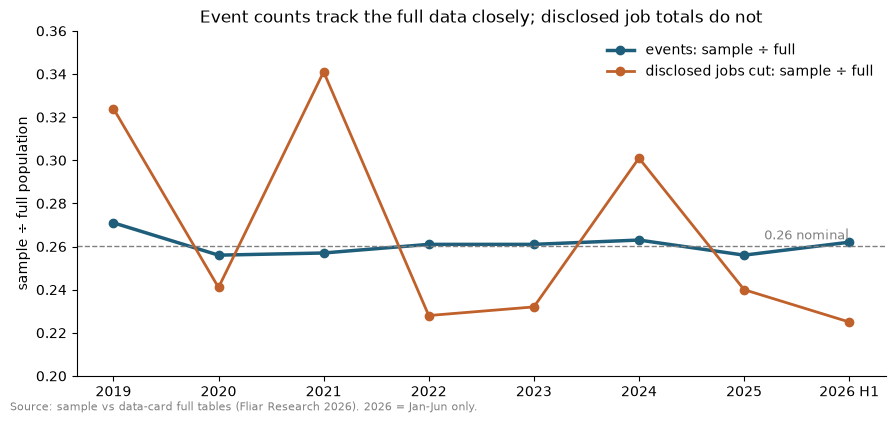

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = bench_year["event_year"].astype(str).str.replace("2026", "2026 H1")
ax.plot(x, bench_year["events_ratio"], marker="o", lw=2.5, color="#1f5e7a", label="events: sample ÷ full")
ax.plot(x, bench_year["jobs_ratio"], marker="o", lw=2, color="#c0612b", label="disclosed jobs cut: sample ÷ full")
ax.axhline(st.NOMINAL_FRACTION, ls="--", color="grey", lw=1)
ax.text(len(x) - 1, st.NOMINAL_FRACTION + 0.003, "0.26 nominal", ha="right", color="grey", fontsize=9)
ax.set_ylim(0.20, 0.36)
ax.set_ylabel("sample ÷ full population")
ax.set_title("Event counts track the full data closely; disclosed job totals do not")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Source: sample vs data-card full tables (Fliar Research 2026). 2026 = Jan-Jun only.", fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_01_sample_vs_full_ratio.png", dpi=150)
plt.show()

**What this shows.**

- **Event counts generalise.** By year the ratio stays between 0.256 and 0.271 (within about ±1 percentage point of 0.260). The top 5 countries (0.248–0.271), the top 3 sectors (0.247–0.269) and the number of repeat companies (0.245) behave the same way. Event-based findings (trends, shares, repeat patterns) can be read as representative of the source.
- **Disclosed job totals do not.** The ratio swings from 0.225 to 0.341. The sample keeps or drops whole companies, so a few very large cuts decide each year's total (for example, Amazon's 99,000 cut in 2022 is not in the sample).
- **Limit of this check.** It validates the sample against the source, not the source against reality. News-based data misses unreported layoffs and favours large, English-covered companies.

## 3. How uncertain are yearly figures? (company-cluster bootstrap)

**Why companies, not rows.** The sample was drawn by company, and events of one company are not independent. Resampling single rows would make intervals too narrow. Each of 1,000 replicates draws 3,467 companies with replacement and keeps all of their events. Intervals are 90% percentile intervals.

In [5]:
boot = st.cluster_bootstrap_yearly(g, n_boot=1000, seed=20261023, level=0.90)
boot.to_csv(STATS_DIR / "bootstrap_yearly.csv", index=False)
print(boot.attrs)
display(boot.round(0))

{'n_boot': 1000, 'seed': 20261023, 'level': 0.9, 'clusters': 3467}


,event_year,events,events_lo,events_hi,disclosed_jobs,disclosed_jobs_lo,disclosed_jobs_hi,median_cut,median_cut_lo,median_cut_hi,partial_year
0,2019,476,437.0,515.0,247634.0,173595.0,326381.0,200.0,172.0,258.0,False
1,2020,968,917.0,1018.0,751961.0,552711.0,978651.0,300.0,250.0,350.0,False
2,2021,265,236.0,293.0,152748.0,93541.0,219878.0,210.0,180.0,314.0,False
3,2022,525,488.0,567.0,193251.0,123977.0,277741.0,142.0,100.0,176.0,False
4,2023,885,834.0,936.0,423496.0,320805.0,528817.0,169.0,142.0,200.0,False
5,2024,791,742.0,840.0,434305.0,320498.0,564546.0,175.0,150.0,202.0,False
6,2025,762,710.0,813.0,416695.0,306330.0,555190.0,200.0,164.0,210.0,False
7,2026,328,300.0,358.0,168818.0,84937.0,266236.0,153.0,115.0,209.0,True


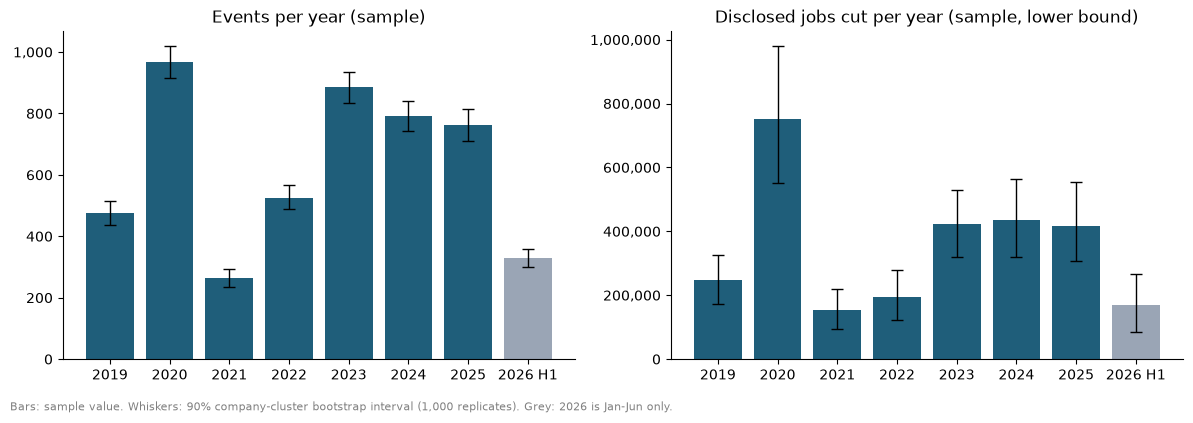

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
yrs = boot["event_year"].astype(str).str.replace("2026", "2026 H1")
colors = ["#9aa5b5" if p else "#1f5e7a" for p in boot["partial_year"]]
for ax, col, title in [(axes[0], "events", "Events per year (sample)"),
                       (axes[1], "disclosed_jobs", "Disclosed jobs cut per year (sample, lower bound)")]:
    err = [boot[col] - boot[f"{col}_lo"], boot[f"{col}_hi"] - boot[col]]
    ax.bar(yrs, boot[col], color=colors)
    ax.errorbar(yrs, boot[col], yerr=err, fmt="none", ecolor="black", capsize=4, lw=1)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Bars: sample value. Whiskers: 90% company-cluster bootstrap interval (1,000 replicates). Grey: 2026 is Jan-Jun only.",
         fontsize=8, color="grey")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG_DIR / "05_02_bootstrap_yearly.png", dpi=150)
plt.show()

In [7]:
overlap = st.overlapping_years(boot, "disclosed_jobs")
overlap.to_csv(STATS_DIR / "bootstrap_jobs_year_overlap.csv", index=False)
print("Full-year pairs whose disclosed-jobs intervals do NOT overlap (order is supported):")
display(overlap[~overlap["intervals_overlap"]])
pairs_2023_25 = overlap[overlap["year_a"].isin([2023, 2024]) & overlap["year_b"].isin([2024, 2025])]
display(pairs_2023_25)
assert pairs_2023_25["intervals_overlap"].all()

Full-year pairs whose disclosed-jobs intervals do NOT overlap (order is supported):


,year_a,year_b,intervals_overlap
0,2019,2020,False
6,2020,2021,False
7,2020,2022,False
8,2020,2023,False
12,2021,2023,False
13,2021,2024,False
14,2021,2025,False
15,2022,2023,False
16,2022,2024,False
17,2022,2025,False


,year_a,year_b,intervals_overlap
18,2023,2024,True
19,2023,2025,True
20,2024,2025,True


**Corrected reading of job totals (replaces the old F3 claim in notebook 03).**

- 2020's disclosed jobs (about 752k) has a lower bound of about 553k, above the upper bound of every other year. **"2020 had the most disclosed job cuts" is supported.**
- 2023, 2024 and 2025 (about 423k, 434k and 417k) have overlapping intervals of roughly 310k–560k. **The sample cannot rank these years.** The full data in fact orders them 2023 > 2025 > 2024, while the sample orders them 2024 > 2023 > 2025.
- Event counts have narrow intervals (about ±5%), so year-to-year event comparisons remain the headline measure.
- Every job figure is a **disclosed, lower-bound** sum for a **sample**. Never scale it up to a market total.

## 4. After a first layoff, how soon does the next one come? (Kaplan-Meier)

**Set-up.** One row per company. The clock starts at the company's **first** event in the sample and stops at its **second** event (the "repeat"). Companies with no second event by **14 June 2026** are **right-censored**: we know they went at least that long without another round, not that they never had one. Kaplan-Meier uses that partial information instead of treating censored companies as "no repeat".

Covariates are taken from the first event: industry group, region, era (first event before or after 2022) and the size of the first cut.

In [8]:
gaps = st.first_gap_table(g)
print(f"companies: {len(gaps):,} | repeat observed: {gaps['event'].sum():,} | censored: {(gaps['event'] == 0).sum():,}")
print(f"share of sampled companies with 2+ rounds: {gaps['event'].mean():.1%} "
      f"(data card, full data: 2,768 of 13,303 = {2768 / 13303:.1%})")
rep = gaps.loc[gaps["event"] == 1, "duration_days"]
print(f"among companies that repeated: median gap {rep.median():.0f} days; gaps under 45 days: {(rep < 45).sum()}")

km_all = st.kaplan_meier(gaps["duration_days"], gaps["event"])
km_all.to_csv(STATS_DIR / "km_curve_overall.csv", index=False)
overall = st.repeat_probabilities(gaps)
overall.to_csv(STATS_DIR / "repeat_probability_overall.csv", index=False)
display(overall)

companies: 3,467 | repeat observed: 688 | censored: 2,779
share of sampled companies with 2+ rounds: 19.8% (data card, full data: 2,768 of 13,303 = 20.8%)
among companies that repeated: median gap 266 days; gaps under 45 days: 1


,group,companies,repeats_observed,p_repeat_182d,p_repeat_182d_lo,p_repeat_182d_hi,p_repeat_365d,p_repeat_365d_lo,p_repeat_365d_hi,p_repeat_730d,p_repeat_730d_lo,p_repeat_730d_hi
0,All companies,3467,688,0.076,0.067,0.085,0.126,0.115,0.138,0.162,0.149,0.175


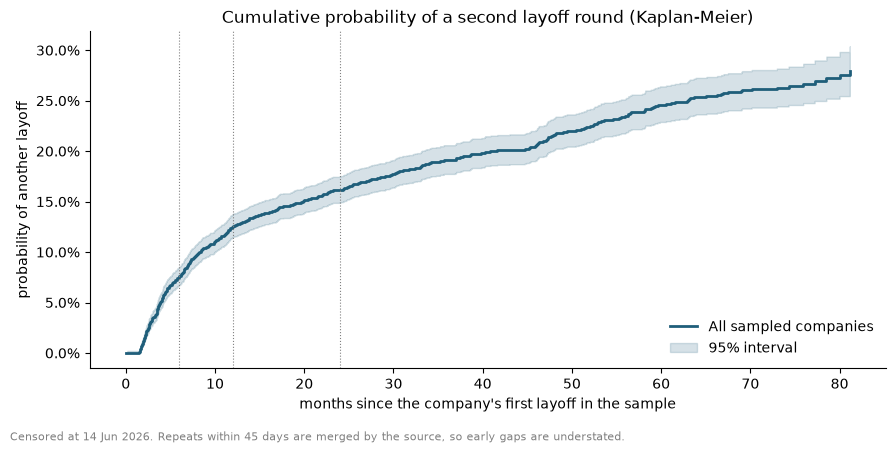

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
months = km_all["t"] / 30.44
ax.step(months, 1 - km_all["survival"], where="post", color="#1f5e7a", lw=2, label="All sampled companies")
ax.fill_between(months, 1 - km_all["hi"], 1 - km_all["lo"], step="post", color="#1f5e7a", alpha=0.18, label="95% interval")
for m in (6, 12, 24):
    ax.axvline(m, color="grey", lw=0.8, ls=":")
ax.set_xlabel("months since the company's first layoff in the sample")
ax.set_ylabel("probability of another layoff")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Cumulative probability of a second layoff round (Kaplan-Meier)")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Censored at 14 Jun 2026. Repeats within 45 days are merged by the source, so early gaps are understated.",
         fontsize=8, color="grey")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG_DIR / "05_03_km_overall.png", dpi=150)
plt.show()

### 4.1 Differences between groups (log-rank tests)

In [10]:
by_industry = st.repeat_probabilities(gaps, by="industry_group", min_n=30).sort_values("p_repeat_365d", ascending=False)
by_era = st.repeat_probabilities(gaps, by="era")
by_size = st.repeat_probabilities(gaps, by="first_cut_size")
by_region = st.repeat_probabilities(gaps, by="region", min_n=30)
for name, t in [("industry", by_industry), ("era", by_era), ("first_cut_size", by_size), ("region", by_region)]:
    t.to_csv(STATS_DIR / f"repeat_probability_by_{name}.csv", index=False)

known = gaps[gaps["industry_group"] != "Unknown"]
tests = pd.DataFrame([
    {"comparison": "industry group (incl. Unknown)", **st.logrank_test(gaps["duration_days"], gaps["event"], gaps["industry_group"])},
    {"comparison": "industry group (known only)", **st.logrank_test(known["duration_days"], known["event"], known["industry_group"])},
    {"comparison": "era of first event", **st.logrank_test(gaps["duration_days"], gaps["event"], gaps["era"])},
    {"comparison": "size of first cut", **st.logrank_test(gaps["duration_days"], gaps["event"], gaps["first_cut_size"])},
])[["comparison", "groups", "chi2", "df", "p_value"]]
tests.to_csv(STATS_DIR / "logrank_tests.csv", index=False)
display(tests)
display(by_era)
display(by_size)
display(by_industry[["group", "companies", "repeats_observed", "p_repeat_365d", "p_repeat_365d_lo", "p_repeat_365d_hi"]])

,comparison,groups,chi2,df,p_value
0,industry group (incl. Unknown),17,144.27,16,1.048126e-22
1,industry group (known only),16,21.37,15,1.255395e-01
2,era of first event,2,0.00,1,9.683755e-01
3,size of first cut,3,44.60,2,2.061580e-10


,group,companies,repeats_observed,p_repeat_182d,p_repeat_182d_lo,p_repeat_182d_hi,p_repeat_365d,p_repeat_365d_lo,p_repeat_365d_hi,p_repeat_730d,p_repeat_730d_lo,p_repeat_730d_hi
0,2019-2021 (incl. COVID),1359,359,0.082,0.068,0.098,0.127,0.111,0.146,0.160,0.141,0.180
1,2022 onwards,2108,329,0.072,0.061,0.084,0.125,0.111,0.141,0.164,0.147,0.182


,group,companies,repeats_observed,p_repeat_182d,p_repeat_182d_lo,p_repeat_182d_hi,p_repeat_365d,p_repeat_365d_lo,p_repeat_365d_hi,p_repeat_730d,p_repeat_730d_lo,p_repeat_730d_hi
0,500 or more,378,107,0.124,0.095,0.162,0.179,0.143,0.223,0.215,0.175,0.262
1,Under 500,1174,277,0.088,0.073,0.106,0.143,0.124,0.165,0.195,0.172,0.220
2,Undisclosed,1915,304,0.059,0.049,0.071,0.105,0.091,0.120,0.130,0.115,0.147


,group,companies,repeats_observed,p_repeat_365d,p_repeat_365d_lo,p_repeat_365d_hi
7,Industrial & Manufacturing,116,37,0.200,0.136,0.287
12,Technology (mixed),51,11,0.186,0.101,0.327
4,Finance & Fintech,233,59,0.178,0.133,0.235
13,Telecom,37,14,0.177,0.083,0.354
14,Travel & Transport,112,31,0.175,0.115,0.260
10,Retail & Consumer,400,119,0.174,0.140,0.216
6,Healthcare & Life Sciences,183,44,0.174,0.125,0.240
3,Energy & Resources,123,33,0.172,0.114,0.254
2,Education & Public Sector,50,11,0.171,0.089,0.314
11,Software & IT,169,39,0.169,0.119,0.236


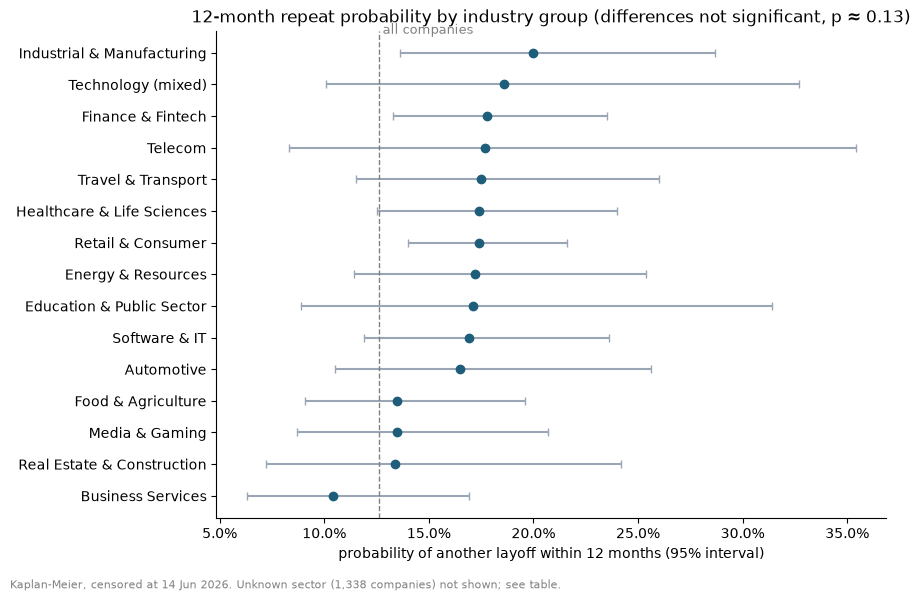

In [11]:
top = by_industry[by_industry["group"] != "Unknown"].sort_values("p_repeat_365d")
fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(top["p_repeat_365d"], top["group"], xerr=[top["p_repeat_365d"] - top["p_repeat_365d_lo"],
            top["p_repeat_365d_hi"] - top["p_repeat_365d"]], fmt="o", color="#1f5e7a", ecolor="#9aa5b5", capsize=3)
ax.axvline(overall["p_repeat_365d"].item(), color="grey", ls="--", lw=1)
ax.text(overall["p_repeat_365d"].item(), len(top) - 0.4, " all companies", color="grey", fontsize=9)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("probability of another layoff within 12 months (95% interval)")
ax.set_title("12-month repeat probability by industry group (differences not significant, p ≈ 0.13)")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Kaplan-Meier, censored at 14 Jun 2026. Unknown sector (1,338 companies) not shown; see table.", fontsize=8, color="grey")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "05_04_repeat_12m_by_industry.png", dpi=150)
plt.show()

**What this shows.**

- **About 1 in 8 sampled companies (12.6%, 95% CI 11.5%–13.8%) had another layoff within 12 months of its first, and about 16% within 24 months.** Among companies that did repeat, the median gap was about 9 months.
- **The size of the first cut matters.** 12-month repeat probability is about 18% after a first cut of 500+ people, 14% after a smaller disclosed cut and 10% when the first cut was undisclosed (log-rank p < 0.001). The 500+ and under-500 intervals overlap, so the clearest gap is disclosed versus undisclosed.
- **The era makes no difference.** Companies whose first event came in 2019–2021 and those from 2022 onwards have almost identical curves (log-rank p ≈ 0.97).
- **Industry differences are not significant once Unknown is set aside.** With Unknown included the test is highly significant, but that is driven by "Unknown sector" companies, which repeat far less (6.6%). They are mostly companies the source could not match to its company database, so they are likely smaller and less covered by news. Among the 16 known groups the log-rank test gives p ≈ 0.13, so **do not rank industries by repeat risk**.
- These are **associations**, not causes, and they describe news-reported layoffs at sampled companies.

**Limitations specific to this analysis.**

1. **Left truncation.** A company's "first" event is its first event since January 2019. Earlier history is invisible.
2. **The 45-day merge.** The source merges reports at one company within 45 days into one event, so very short gaps are undercounted.
3. **Split company names.** Large brands can appear under several names (for example, Disney under 5), which hides some repeats. Names are not merged without evidence.
4. **Censoring assumption.** Kaplan-Meier assumes companies censored in 2026 have the same repeat risk as earlier ones. News ingest thins after May 2026, which could understate late repeats slightly.

## 5. Findings for the dashboard and README

| # | Finding | Support |
|---|---|---|
| S1 | The 26% sample reproduces full-data **event counts** within about ±1 pp by year, top country, top sector and repeat-company count. | Strong: external benchmark (data card) |
| S2 | Sample **disclosed-job totals** do not track the full data (ratio 0.225–0.341), so they are lower bounds for the sample only and years 2023–2025 cannot be ranked. Only "2020 had the most disclosed cuts" survives the bootstrap. | Strong: benchmark + 90% cluster bootstrap |
| S3 | About **12.6%** of companies lay off again within 12 months of their first sampled layoff (**16.2%** within 24 months), with 95% intervals. | Moderate: Kaplan-Meier with censoring; left truncation and name splits |
| S4 | Repeat risk is higher after a disclosed first cut (about 18% for 500+, 14% under 500) than after an undisclosed one (10%). Era and known industry group show no significant difference. | Moderate: log-rank tests; association only |

## 6. What was deliberately not built

- **Severity classifier.** The audit's throwaway probe reached ROC-AUC about 0.63–0.64, and the target exists only for the non-random half of events with a disclosed headcount.
- **Monthly forecast.** About 90 monthly points, a COVID shock and incomplete 2026 would mostly forecast artefacts.
- **"AI layoffs" page.** Only 41 global news excerpts mention AI, and the tech file's AI label is undefined.

In [12]:
print("Outputs written:")
for p in sorted(STATS_DIR.glob("*.csv")) + sorted(FIG_DIR.glob("05_*.png")):
    print(" ", p.relative_to(PROJECT_ROOT))

Outputs written:
  reports\stats\benchmark_by_year.csv
  reports\stats\benchmark_categories.csv
  reports\stats\bootstrap_jobs_year_overlap.csv
  reports\stats\bootstrap_yearly.csv
  reports\stats\km_curve_overall.csv
  reports\stats\logrank_tests.csv
  reports\stats\repeat_probability_by_era.csv
  reports\stats\repeat_probability_by_first_cut_size.csv
  reports\stats\repeat_probability_by_industry.csv
  reports\stats\repeat_probability_by_region.csv
  reports\stats\repeat_probability_overall.csv
  reports\figures\05_01_sample_vs_full_ratio.png
  reports\figures\05_02_bootstrap_yearly.png
  reports\figures\05_03_km_overall.png
  reports\figures\05_04_repeat_12m_by_industry.png
